# PathPack-H: локализация правок, обученная на истории репозитория

Все числа читаются из сохранённых прогонов:

- `output/pathpack_val_all`: validation, 99 непросмотренных задач (использован для выбора варианта);
- `output/pathpack_holdout`: final holdout, 100 задач, один прогон после заморозки `output/pathpack_e/FREEZE_before_holdout.json`.

Токены условные: `ceil(UTF-8 bytes / 4)`. Это не токенизатор Gemma. Долю исправленных ошибок ноутбук не измеряет.

In [1]:
import csv, gzip, json, collections
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / 'output').is_dir() else Path.cwd().parent
VAL, HOLD = ROOT / 'output/pathpack_val_all', ROOT / 'output/pathpack_holdout'
SURFACE, INK, MUTED, GRID = '#fcfcfb', '#1f1f1e', '#6b6a64', '#e4e3de'
BLUE, ORANGE, AQUA, YELLOW, NEUTRAL = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#b9b8b1'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
                     'axes.edgecolor': GRID, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': INK,
                     'text.color': INK, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.spines.left': False, 'axes.grid': False, 'figure.dpi': 110})
METRICS = [('file_recall', 'File Recall'), ('function_recall', 'Function Recall'),
           ('complete_function_recall', 'Complete Function Recall'), ('changed_line_recall', 'Changed Line Recall')]
NAMES = {'bm25': 'BM25', 'pathpack-v4': 'PathPack v0.4', 'pathpack-v10e': 'v1.0e (исправленная остановка)',
         'pathpack-r/fusion': 'Fusion (ручная формула)', 'pathpack-e': 'PathPack-E (метки, 34 задачи)',
         'pathpack-h': 'PathPack-H с памятью коммитов', 'pathpack-h/nomemory': 'PathPack-H (основной)',
         'pathpack-h/nohist': 'H без признаков истории', 'pathpack-h/nograph': 'H без графового раунда',
         'pathpack-h/ranked': 'H, упаковка ранжированием', 'pathpack-h/skeleton': 'H со скелетами',
         'pathpack-eh': 'PathPack-EH (метки + история)', 'pathpack-r/fusion-epack': 'Fusion + упаковка по покрытию',
         'pathpack-r': 'PathPack-R (reranker + active)', 'pathpack-r/reranker-graph': 'Reranker MS-MARCO + граф'}
PRIMARY = 'pathpack-h/nomemory'

def summary(run):
    df = pd.read_csv(run / 'summary.csv')
    return df

def scores(run):
    return pd.DataFrame([json.loads(l) for l in open(run / 'scores.jsonl')])

freeze = json.load(open(ROOT / 'output/pathpack_e/FREEZE_before_holdout.json'))
print('Основной вариант (выбран по validation до holdout):', freeze['primary'])
print('Правило выбора:', freeze['selection_rule'])

Основной вариант (выбран по validation до holdout): pathpack-h/nomemory
Правило выбора: File >= v0.4 - 0.05 and at least two of Function/Complete/ChangedLine above v0.4 with 95% CI excluding 0, at budget 2048, on validation (99 tasks)


## 1. Итог на holdout при бюджете 2048

Одна панель на метрику, общий порядок методов. Синим выделен основной вариант, выбранный до прогона. Остальные методы серые: идентичность несёт подпись строки.

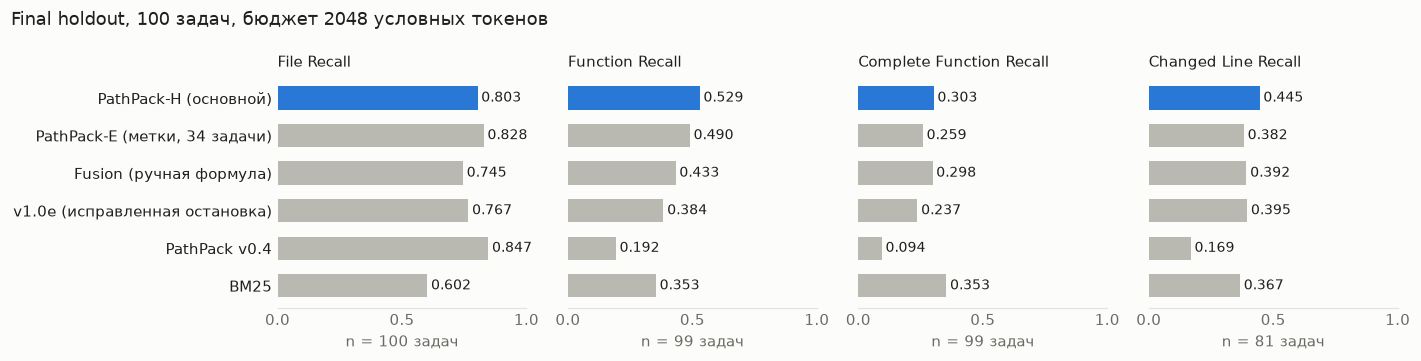

,file_recall,function_recall,complete_function_recall,changed_line_recall
method,,,,
PathPack-H (основной),0.803,0.529,0.303,0.445
"PathPack-E (метки, 34 задачи)",0.828,0.490,0.259,0.382
Fusion (ручная формула),0.745,0.433,0.298,0.392
v1.0e (исправленная остановка),0.767,0.384,0.237,0.395
PathPack v0.4,0.847,0.192,0.094,0.169
BM25,0.602,0.353,0.353,0.367


In [2]:
hold = summary(HOLD)
order = [PRIMARY, 'pathpack-e', 'pathpack-r/fusion', 'pathpack-v10e', 'pathpack-v4', 'bm25']
at = hold[hold.budget == 2048].set_index('method').loc[order]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3), sharey=True)
for ax, (key, title) in zip(axes, METRICS):
    vals = at[key].values
    bars = ax.barh(range(len(order)), vals, height=0.62, color=[BLUE if m == PRIMARY else NEUTRAL for m in order])
    for i, v in enumerate(vals):
        ax.text(v + 0.015, i, f'{v:.3f}', va='center', fontsize=9, color=INK)
    ax.set_xlim(0, 1); ax.set_title(title, fontsize=10, loc='left', color=INK)
    ax.set_yticks(range(len(order))); ax.set_yticklabels([NAMES[m] for m in order])
    ax.set_xticks([0, 0.5, 1]); ax.tick_params(length=0)
    n = int(at[key + '_evaluable'].iloc[0]); ax.set_xlabel(f'n = {n} задач')
axes[0].invert_yaxis()
fig.suptitle('Final holdout, 100 задач, бюджет 2048 условных токенов', x=0.01, ha='left', fontsize=12)
fig.tight_layout(); plt.show()
at[[k for k, _ in METRICS]].rename(index=NAMES).round(3)

## 2. Парные разницы с доверительными интервалами

Точка: средняя разница по задачам, отрезок: 95% интервал парного bootstrap по задачам (2000 итераций, seed 42). Для основных сравнений ниже отдельной таблицей дан интервал с кластеризацией по репозиториям.

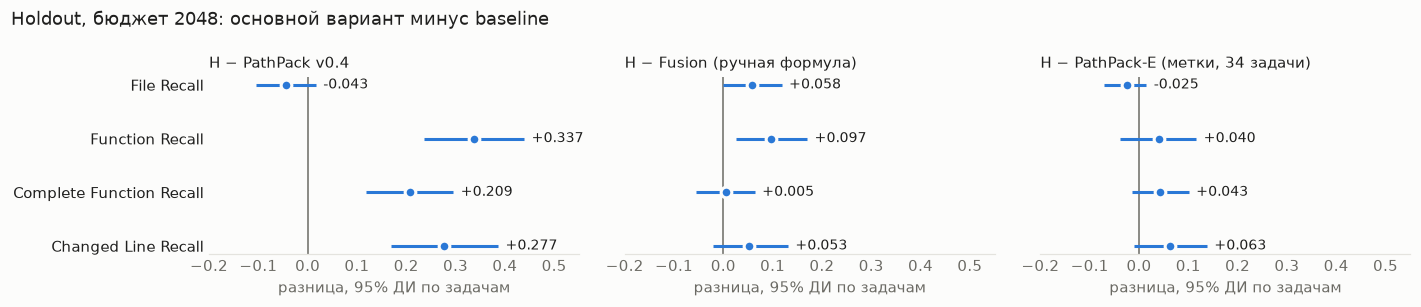

,сравнение,метрика,diff,lo,hi,n,wins,ties,losses
0,H − PathPack v0.4,File Recall,-0.043,-0.105,0.017,100,4,85,11
1,H − PathPack v0.4,Function Recall,0.337,0.237,0.439,99,42,52,5
2,H − PathPack v0.4,Complete Function Recall,0.209,0.119,0.295,99,27,68,4
3,H − PathPack v0.4,Changed Line Recall,0.277,0.169,0.386,81,34,41,6
4,H − Fusion (ручная формула),File Recall,0.058,-0.002,0.118,100,10,87,3
5,H − Fusion (ручная формула),Function Recall,0.097,0.026,0.170,99,14,81,4
6,H − Fusion (ручная формула),Complete Function Recall,0.005,-0.056,0.064,99,6,87,6
7,H − Fusion (ручная формула),Changed Line Recall,0.053,-0.021,0.131,81,13,61,7
8,"H − PathPack-E (метки, 34 задачи)",File Recall,-0.025,-0.070,0.015,100,2,93,5
9,"H − PathPack-E (метки, 34 задачи)",Function Recall,0.040,-0.040,0.116,99,14,76,9


In [3]:
import random
def paired(df, cand, base, metric, budget=2048, iters=2000, seed=42):
    a = df[(df.method == cand) & (df.budget == budget)].set_index('instance_id')[metric].dropna()
    b = df[(df.method == base) & (df.budget == budget)].set_index('instance_id')[metric].dropna()
    ids = sorted(set(a.index) & set(b.index)); d = [a[i] - b[i] for i in ids]
    rng = random.Random(seed); bs = sorted(sum(rng.choice(d) for _ in d) / len(d) for _ in range(iters))
    return dict(diff=sum(d) / len(d), lo=bs[int(0.025 * iters)], hi=bs[int(0.975 * iters) - 1], n=len(d),
                wins=sum(x > 0 for x in d), ties=sum(x == 0 for x in d), losses=sum(x < 0 for x in d))

hs = scores(HOLD)
rows = []
for base in ('pathpack-v4', 'pathpack-r/fusion', 'pathpack-e'):
    for key, title in METRICS:
        rows.append({'сравнение': f'H − {NAMES[base]}', 'метрика': title, **paired(hs, PRIMARY, base, key)})
cmp = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8), sharex=True, sharey=True)
for ax, (name, part) in zip(axes, cmp.groupby('сравнение', sort=False)):
    y = range(len(part))
    ax.axvline(0, color=MUTED, lw=1)
    ax.hlines(y, part.lo, part.hi, color=BLUE, lw=2)
    ax.plot(part['diff'], y, 'o', color=BLUE, ms=7, mec=SURFACE, mew=2)
    for i, r in enumerate(part.itertuples()):
        ax.text(r.hi + 0.015, i, f'{r.diff:+.3f}', va='center', fontsize=9)
    ax.set_yticks(list(y)); ax.set_yticklabels(part['метрика'])
    ax.set_title(name, fontsize=10, loc='left'); ax.tick_params(length=0); ax.set_xlim(-0.2, 0.55)
    ax.set_xlabel('разница, 95% ДИ по задачам')
axes[0].invert_yaxis()
fig.suptitle('Holdout, бюджет 2048: основной вариант минус baseline', x=0.01, ha='left', fontsize=12)
fig.tight_layout(); plt.show()
cmp.round(3)

In [4]:
cluster = json.load(open(HOLD / 'cluster_bootstrap.json'))
pd.DataFrame([{'сравнение': k.rsplit(' ', 1)[0], 'метрика': k.rsplit(' ', 1)[1], 'разница': round(v['difference'], 3),
               'ДИ по репозиториям': [round(x, 3) for x in v['ci95_repo_cluster']], 'кластеров': v['repos']}
              for k, v in cluster.items()])

,сравнение,метрика,разница,ДИ по репозиториям,кластеров
0,pathpack-h/nomemory vs pathpack-v4,file_recall,-0.043,"[-0.167, 0.019]",9
1,pathpack-h/nomemory vs pathpack-v4,function_recall,0.337,"[0.095, 0.404]",9
2,pathpack-h/nomemory vs pathpack-v4,complete_function_recall,0.209,"[0.034, 0.263]",9
3,pathpack-h/nomemory vs pathpack-v4,changed_line_recall,0.277,"[0.049, 0.334]",9
4,pathpack-h/nomemory vs pathpack-r/fusion,file_recall,0.058,"[-0.018, 0.127]",9
5,pathpack-h/nomemory vs pathpack-r/fusion,function_recall,0.097,"[0.0, 0.219]",9
6,pathpack-h/nomemory vs pathpack-r/fusion,complete_function_recall,0.005,"[-0.045, 0.096]",9
7,pathpack-h/nomemory vs pathpack-r/fusion,changed_line_recall,0.053,"[-0.024, 0.174]",9


## 3. Зависимость от бюджета

Проверка, что вывод не привязан к одному бюджету. У v0.4 покрытие функций и строк почти не растёт с бюджетом: лишние токены уходят на новые файлы.

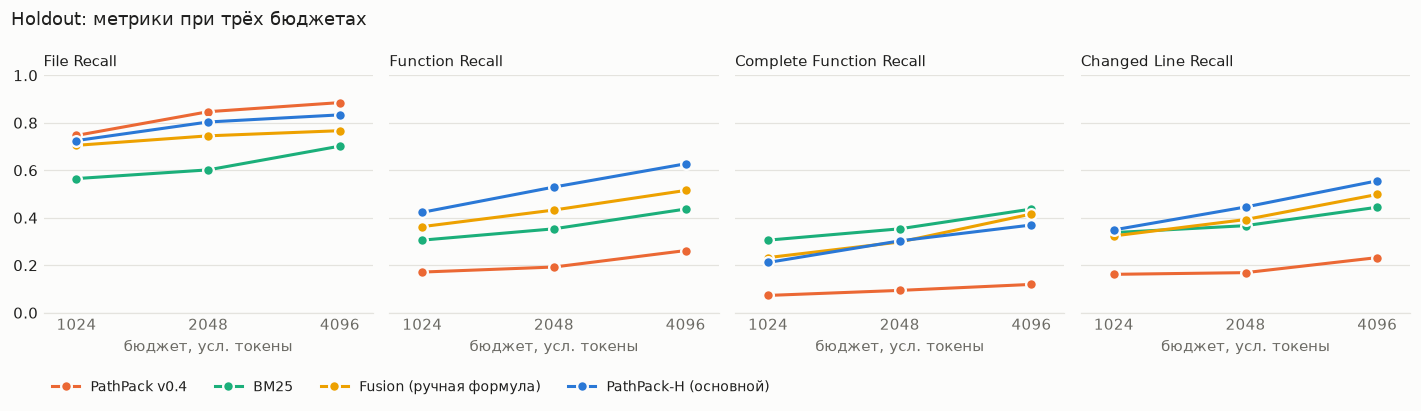

file_recall               function_recall         \
budget                         1024   2048   4096            1024   2048   
method                                                                     
BM25                          0.565  0.602  0.702           0.306  0.353   
PathPack-H (основной)         0.725  0.803  0.833           0.423  0.529   
Fusion (ручная формула)       0.705  0.745  0.767           0.363  0.433   
PathPack v0.4                 0.747  0.847  0.885           0.171  0.192   

                               complete_function_recall                \
budget                    4096                     1024   2048   4096   
method                                                                  
BM25                     0.437                    0.306  0.353  0.437   
PathPack-H (основной)    0.627                    0.212  0.303  0.370   
Fusion (ручная формула)  0.515                    0.232  0.298  0.416   
PathPack v0.4            0.262                    0.073  0.094  0.119   

                        changed_line_recall                
budget                                 1024   2048   4096  
method                                                     
BM25                                  0.337  0.367  0.444  
PathPack-H (основной)                 0.349  0.445  0.556  
Fusion (ручная формула)               0.323  0.392  0.498  
PathPack v0.4                         0.162  0.169  0.232

In [5]:
lines = [('pathpack-v4', ORANGE), ('bm25', AQUA), ('pathpack-r/fusion', YELLOW), (PRIMARY, BLUE)]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
pos = {1024: 0, 2048: 1, 4096: 2}
for ax, (key, title) in zip(axes, METRICS):
    for method, color in lines:
        part = hold[hold.method == method].sort_values('budget')
        ax.plot([pos[b] for b in part.budget], part[key], color=color, lw=2, marker='o', ms=7, mec=SURFACE, mew=1.5,
                label=NAMES[method])
    ax.set_xticks([0, 1, 2]); ax.set_xticklabels(['1024', '2048', '4096']); ax.set_xlim(-0.25, 2.25); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10, loc='left'); ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
    ax.tick_params(length=0); ax.set_xlabel('бюджет, усл. токены')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=9, ncol=4, loc='lower left', bbox_to_anchor=(0.03, -0.02))
fig.suptitle('Holdout: метрики при трёх бюджетах', x=0.01, ha='left', fontsize=12)
fig.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()
hold[hold.method.isin([m for m, _ in lines])].pivot(index='method', columns='budget', values=[k for k, _ in METRICS]).rename(index=NAMES).round(3)

## 4. Абляции: что в PathPack-H даёт вклад

Слева validation (по нему выбирался вариант), справа holdout. Различия между вариантами H малы относительно интервалов; это вторичный анализ без поправки на множественные сравнения.

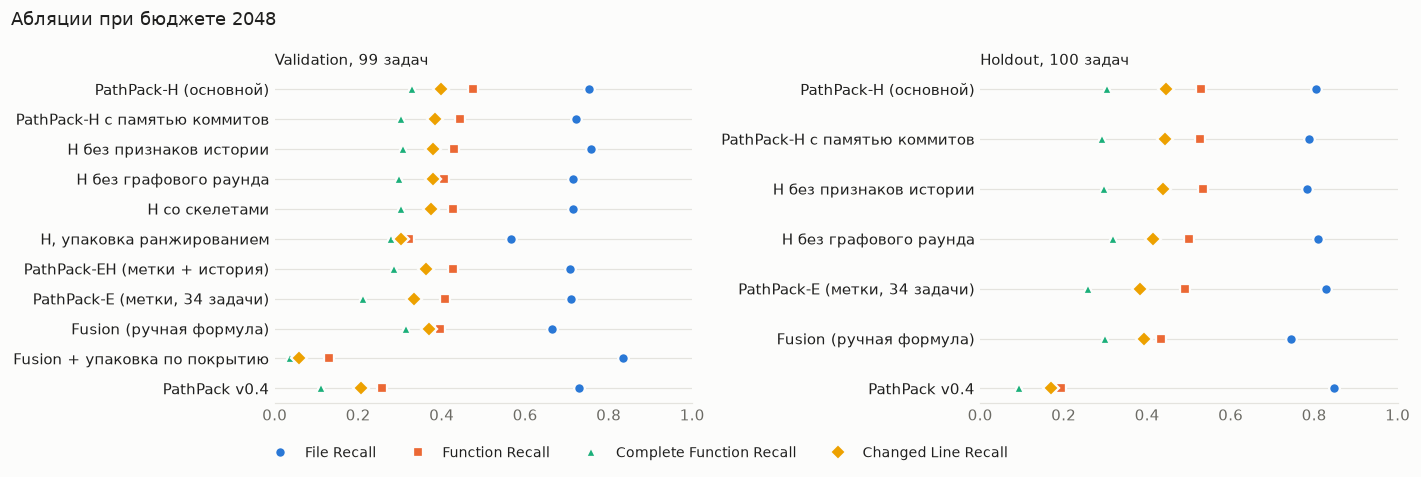

,file_recall,function_recall,complete_function_recall,changed_line_recall
method,,,,
PathPack-H (основной),0.752,0.474,0.329,0.399
PathPack-H с памятью коммитов,0.722,0.444,0.303,0.383
H без признаков истории,0.757,0.429,0.306,0.379
H без графового раунда,0.714,0.406,0.298,0.379
H со скелетами,0.715,0.427,0.303,0.374
"H, упаковка ранжированием",0.565,0.321,0.279,0.303
PathPack-EH (метки + история),0.707,0.427,0.286,0.363
"PathPack-E (метки, 34 задачи)",0.710,0.408,0.211,0.335
Fusion (ручная формула),0.665,0.396,0.315,0.371


,file_recall,function_recall,complete_function_recall,changed_line_recall
method,,,,
PathPack-H (основной),0.803,0.529,0.303,0.445
PathPack-H с памятью коммитов,0.788,0.526,0.293,0.443
H без признаков истории,0.783,0.534,0.298,0.437
H без графового раунда,0.808,0.499,0.318,0.413
"PathPack-E (метки, 34 задачи)",0.828,0.490,0.259,0.382
Fusion (ручная формула),0.745,0.433,0.298,0.392
PathPack v0.4,0.847,0.192,0.094,0.169


In [6]:
val = summary(VAL)
abl_val = ['pathpack-h/nomemory', 'pathpack-h', 'pathpack-h/nohist', 'pathpack-h/nograph', 'pathpack-h/skeleton',
           'pathpack-h/ranked', 'pathpack-eh', 'pathpack-e', 'pathpack-r/fusion', 'pathpack-r/fusion-epack', 'pathpack-v4']
abl_hold = [m for m in abl_val if m in set(hold.method)]
def table(df, methods):
    return df[df.budget == 2048].set_index('method').loc[methods][[k for k, _ in METRICS]].rename(index=NAMES).round(3)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
marks = dict(zip([k for k, _ in METRICS], [(BLUE, 'o'), (ORANGE, 's'), (AQUA, '^'), (YELLOW, 'D')]))
for ax, (df, methods, title) in zip(axes, [(val, abl_val, 'Validation, 99 задач'), (hold, abl_hold, 'Holdout, 100 задач')]):
    t = df[df.budget == 2048].set_index('method').loc[methods]
    for i in range(len(methods)):
        ax.axhline(i, color=GRID, lw=0.8, zorder=0)
    for key, label in METRICS:
        color, marker = marks[key]
        ax.plot(t[key], range(len(methods)), marker, color=color, ms=7, mec=SURFACE, mew=1.5, label=label)
    ax.set_yticks(range(len(methods))); ax.set_yticklabels([NAMES[m] for m in methods]); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.set_title(title, fontsize=10, loc='left'); ax.tick_params(length=0)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=9, ncol=4, loc='lower left', bbox_to_anchor=(0.18, -0.02))
fig.suptitle('Абляции при бюджете 2048', x=0.01, ha='left', fontsize=12)
fig.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()
display(table(val, abl_val)); table(hold, abl_hold)

## 5. Где теряется код: пул против упакованного контекста

Доля золотых файлов и функций в пуле кандидатов и в итоговом контексте (holdout, 2048). Пул у всех вариантов PathPack-R/E/H общий, различается выбор из него.

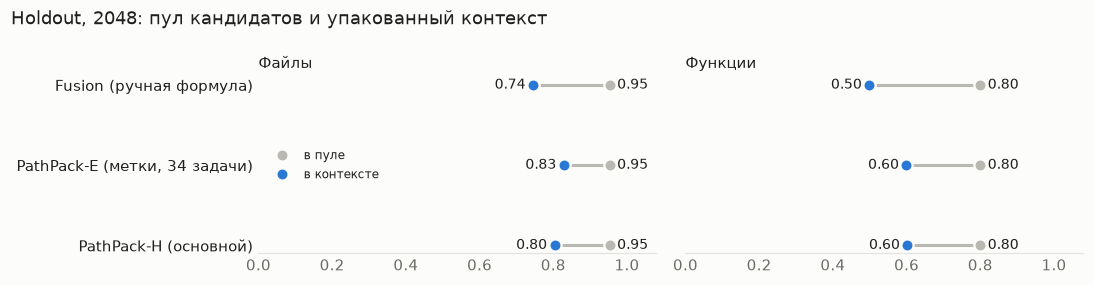

,file_pool_recall,file_packed_recall,function_pool_recall,function_packed_recall
method,,,,
Fusion (ручная формула),0.953,0.745,0.8,0.499
"PathPack-E (метки, 34 задачи)",0.953,0.828,0.8,0.600
PathPack-H (основной),0.953,0.803,0.8,0.602


In [7]:
pool = pd.read_csv(HOLD / 'pool_recall.csv'); pool = pool[pool.budget == 2048]
agg = pool.groupby('method')[['file_pool_recall', 'file_packed_recall', 'function_pool_recall', 'function_packed_recall']].mean()
show = [m for m in ['pathpack-r/fusion', 'pathpack-e', PRIMARY] if m in agg.index]
fig, axes = plt.subplots(1, 2, figsize=(10, 2.6), sharey=True)
for ax, (kind, title) in zip(axes, [('file', 'Файлы'), ('function', 'Функции')]):
    for i, m in enumerate(show):
        p, k = agg.loc[m, f'{kind}_pool_recall'], agg.loc[m, f'{kind}_packed_recall']
        ax.hlines(i, k, p, color=NEUTRAL, lw=2)
        ax.plot(p, i, 'o', color=NEUTRAL, ms=8, mec=SURFACE, mew=1.5, label='в пуле' if i == 0 else None)
        ax.plot(k, i, 'o', color=BLUE, ms=8, mec=SURFACE, mew=1.5, label='в контексте' if i == 0 else None)
        ax.text(p + 0.02, i, f'{p:.2f}', va='center', fontsize=9); ax.text(k - 0.02, i, f'{k:.2f}', va='center', ha='right', fontsize=9)
    ax.set_yticks(range(len(show))); ax.set_yticklabels([NAMES[m] for m in show])
    ax.set_xlim(0, 1.08); ax.set_title(title, fontsize=10, loc='left'); ax.tick_params(length=0)
axes[0].invert_yaxis(); axes[0].legend(frameon=False, fontsize=8, loc='center left', bbox_to_anchor=(0.0, 0.5))
fig.suptitle('Holdout, 2048: пул кандидатов и упакованный контекст', x=0.01, ha='left', fontsize=12)
fig.tight_layout(); plt.show()
agg.loc[show].rename(index=NAMES).round(3)

## 6. Неоднородность по репозиториям

Средняя разница Function Recall «основной вариант минус v0.4» по репозиториям holdout. Число задач подписано: в малых репозиториях по 1 to 6 задач, выводы по ним ненадёжны.

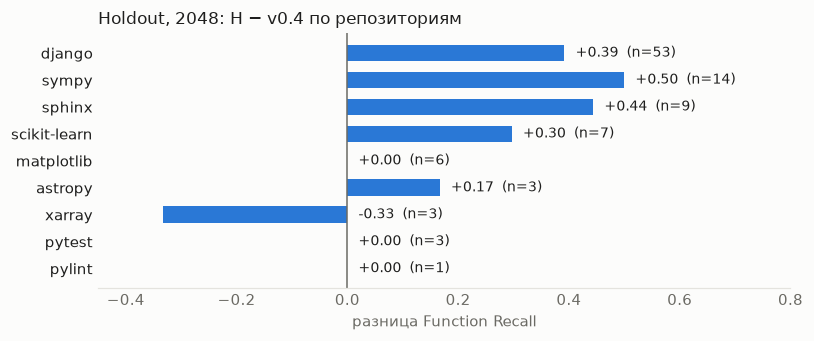

,diff,n
django__django,0.392,53
sympy__sympy,0.500,14
sphinx-doc__sphinx,0.444,9
scikit-learn__scikit-learn,0.297,7
matplotlib__matplotlib,0.000,6
astropy__astropy,0.167,3
pydata__xarray,-0.333,3
pytest-dev__pytest,0.000,3
pylint-dev__pylint,0.000,1


In [8]:
key = 'pathpack-h/nomemory vs pathpack-v4 function_recall'
per = pd.DataFrame({'diff': cluster[key]['per_repo_mean_diff'], 'n': cluster[key]['per_repo_n']}).sort_values('n', ascending=False)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.axvline(0, color=MUTED, lw=1)
ax.barh(range(len(per)), per['diff'], height=0.6, color=BLUE)
for i, r in enumerate(per.itertuples()):
    ax.text(max(r.diff, 0) + 0.02, i, f'{r.diff:+.2f}  (n={r.n})', va='center', fontsize=9)
ax.set_yticks(range(len(per))); ax.set_yticklabels([i.split('__')[-1] for i in per.index]); ax.invert_yaxis()
ax.set_xlim(-0.45, 0.8); ax.tick_params(length=0); ax.set_xlabel('разница Function Recall')
ax.set_title('Holdout, 2048: H − v0.4 по репозиториям', fontsize=11, loc='left')
fig.tight_layout(); plt.show(); per.round(3)

## 7. Откуда обучающие примеры PathPack-H

Псевдо-задачи из коммитов, предшествующих самой ранней задаче Verified в каждом репозитории. Метки бенчмарка не использовались.

In [9]:
plan = json.load(open(ROOT / 'output/pathpack_e/replay_logs/plan.json'))
done = {p.stem: json.load(open(p)) for p in (ROOT / 'output/pathpack_e/train_history').glob('*.done')}
rep = pd.DataFrame([{'репозиторий': i['repo'], 'снимок': i['instance_id'],
                     'граница (UTC)': pd.to_datetime(i['cutoff'], unit='s').date(),
                     'коммитов в логе': done.get(i['repo'].replace('/', '__'), {}).get('commits'),
                     'псевдо-задач': done.get(i['repo'].replace('/', '__'), {}).get('kept'),
                     'фрагментов в снимке': done.get(i['repo'].replace('/', '__'), {}).get('chunks')} for i in plan])
print('всего псевдо-задач:', int(rep['псевдо-задач'].sum()))
print('пакетов логов, не скачанных в частичном клоне:', open(ROOT / 'output/pathpack_e/replay_fetch.log').read().count('failed:'))
rep

всего псевдо-задач: 1295
пакетов логов, не скачанных в частичном клоне: 47


,репозиторий,снимок,граница (UTC),коммитов в логе,псевдо-задач,фрагментов в снимке
0,astropy/astropy,astropy__astropy-7166,2018-02-07,280,120,14250
1,django/django,django__django-7530,2016-11-08,220,120,12308
2,matplotlib/matplotlib,matplotlib__matplotlib-13989,2019-04-19,220,119,16462
3,mwaskom/seaborn,mwaskom__seaborn-3069,2022-10-09,200,120,2789
4,pallets/flask,pallets__flask-5014,2023-03-04,200,108,855
5,psf/requests,psf__requests-1142,2013-01-25,200,56,1593
6,pydata/xarray,pydata__xarray-3151,2019-04-17,200,120,4296
7,pylint-dev/pylint,pylint-dev__pylint-4551,2021-06-07,200,77,2896
8,pytest-dev/pytest,pytest-dev__pytest-5262,2019-05-14,220,120,3009
9,scikit-learn/scikit-learn,scikit-learn__scikit-learn-10297,2017-07-06,280,120,12446


## 8. Один пример: что выбрал алгоритм

Первая задача holdout, где основной вариант покрыл изменённые строки, а v0.4 нет. Показаны выбранные фрагменты с вероятностью правки.

In [10]:
a = hs[(hs.method == PRIMARY) & (hs.budget == 2048)].set_index('instance_id')
b = hs[(hs.method == 'pathpack-v4') & (hs.budget == 2048)].set_index('instance_id')
better = [i for i in a.index if pd.notna(a.loc[i, 'changed_line_recall']) and a.loc[i, 'changed_line_recall'] > b.loc[i, 'changed_line_recall']]
iid = sorted(better)[0]
issue = next(json.loads(l) for l in open(ROOT / 'output/pathpack_r_splits_v2/final_holdout_100_issues.jsonl') if json.loads(l)['instance_id'] == iid)
print(iid); print(issue['problem_statement'][:700], '...')
print('Changed Line Recall: H =', a.loc[iid, 'changed_line_recall'], '| v0.4 =', b.loc[iid, 'changed_line_recall'])
diag = json.load(gzip.open(HOLD / 'diagnostics' / f"{iid}_{PRIMARY.replace('/', '_')}_2048.json.gz", 'rt'))
cand = pd.DataFrame(diag['candidates'])
sel = cand[cand.decision == 'selected'].sort_values('final_score', ascending=False)
print('кандидатов в пуле:', len(cand), '| выбрано:', len(sel), '| файлов:', sel.path.nunique())
sel[['path', 'function', 'line_start', 'line_end', 'token_cost', 'final_score', 'channels']].head(15).round(3)

astropy__astropy-14508
`io.fits.Card` may use a string representation of floats that is larger than necessary
### Description

In some scenarios, `io.fits.Card` may use a string representation of floats that is larger than necessary, which can force comments to be truncated. Due to this, there are some keyword/value/comment combinations that are impossible to create via `io.fits` even though they are entirely possible in FITS.

### Expected behavior

Being able to create any valid FITS Card via `io.fits.Card`.

### How to Reproduce

[This valid FITS file](https://github.com/astropy/astropy/files/10922976/test.fits.gz) contains the following card in the header:

`HIERARCH ESO IFM CL RADIUS = 0.009125 / [m] radius ...
Changed Line Recall: H = 0.11764705882352941 | v0.4 = 0.0
кандидатов в пуле: 301 | выбрано: 24 | файлов: 3


,path,function,line_start,line_end,token_cost,final_score,channels
144,astropy/io/fits/card.py,Card.keyword,233,237,90,0.608,[symbol]
147,astropy/io/fits/card.py,Card.keyword,249,251,67,0.509,[symbol]
149,astropy/io/fits/card.py,Card.keyword,275,282,107,0.505,[symbol]
145,astropy/io/fits/card.py,Card.keyword,236,243,139,0.498,[symbol]
148,astropy/io/fits/card.py,Card.keyword,259,263,89,0.475,[symbol]
151,astropy/io/fits/card.py,Card._format_image,1009,1018,78,0.340,[symbol]
150,astropy/io/fits/card.py,Card._format_image,995,1010,124,0.333,[symbol]
152,astropy/io/fits/card.py,Card._format_image,1040,1042,53,0.330,[symbol]
16,astropy/io/fits/hdu/base.py,_ValidHDU.req_cards,1151,1160,126,0.310,"[lexical, lexical_name]"
26,astropy/io/fits/hdu/base.py,_ValidHDU.req_cards,1175,1188,143,0.310,"[lexical, lexical_name]"


## 9. PathPack-U на втором отложенном наборе

PathPack-U добавляет к модели фрагмента вероятности правки функции и файла и упаковывает контекст, максимизируя сумму ожидаемых File, Function, Complete и Changed Line Recall. Он оценивался на 51 задаче, не входившей в первый holdout (`output/pathpack_holdout2`, заморозка `FREEZE_before_holdout2.json`). Набор мал, интервалы широкие.

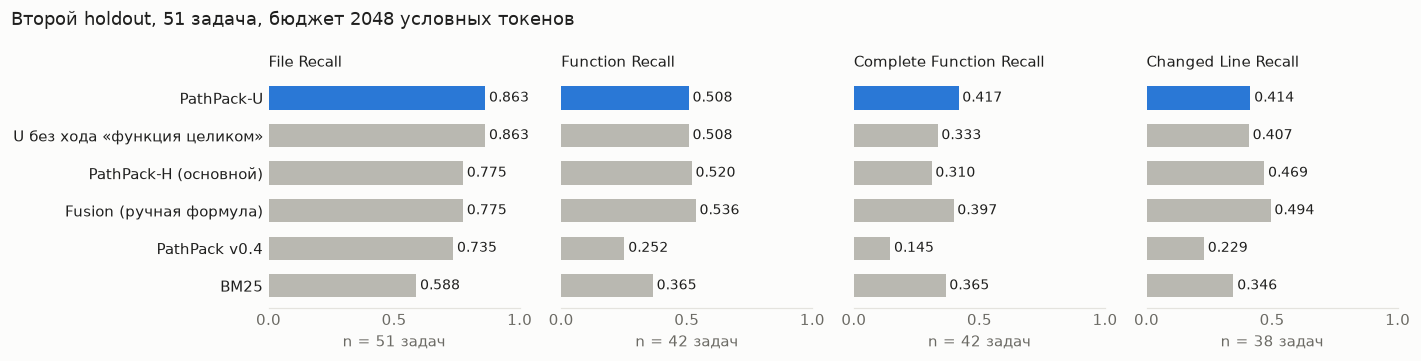

file_recall               function_recall         \
budget                              1024   2048   4096            1024   2048   
method                                                                          
BM25                               0.471  0.588  0.569           0.220  0.365   
PathPack-H (основной)              0.755  0.775  0.814           0.385  0.520   
Fusion (ручная формула)            0.706  0.775  0.814           0.373  0.536   
PathPack-U                         0.863  0.863  0.863           0.411  0.508   
U без хода «функция целиком»       0.843  0.863  0.863           0.379  0.508   
PathPack v0.4                      0.618  0.735  0.892           0.157  0.252   

                                    complete_function_recall                \
budget                         4096                     1024   2048   4096   
method                                                                       
BM25                          0.413                    0.220  0.365  0.413   
PathPack-H (основной)         0.609                    0.226  0.310  0.514   
Fusion (ручная формула)       0.563                    0.254  0.397  0.468   
PathPack-U                    0.667                    0.315  0.417  0.575   
U без хода «функция целиком»  0.663                    0.260  0.333  0.524   
PathPack v0.4                 0.339                    0.073  0.145  0.232   

                             changed_line_recall                
budget                                      1024   2048   4096  
method                                                          
BM25                                       0.223  0.346  0.399  
PathPack-H (основной)                      0.294  0.469  0.534  
Fusion (ручная формула)                    0.338  0.494  0.523  
PathPack-U                                 0.345  0.414  0.559  
U без хода «функция целиком»               0.295  0.407  0.551  
PathPack v0.4                              0.173  0.229  0.308

In [11]:
H2 = ROOT / 'output/pathpack_holdout2'
NAMES['pathpack-u'] = 'PathPack-U'; NAMES['pathpack-u/nobundle'] = 'U без хода «функция целиком»'
h2 = summary(H2)
order2 = ['pathpack-u', 'pathpack-u/nobundle', 'pathpack-h/nomemory', 'pathpack-r/fusion', 'pathpack-v4', 'bm25']
at2 = h2[h2.budget == 2048].set_index('method').loc[order2]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3), sharey=True)
for ax, (key, title) in zip(axes, METRICS):
    vals = at2[key].values
    ax.barh(range(len(order2)), vals, height=0.62, color=[BLUE if m == 'pathpack-u' else NEUTRAL for m in order2])
    for i, v in enumerate(vals):
        ax.text(v + 0.015, i, f'{v:.3f}', va='center', fontsize=9, color=INK)
    ax.set_xlim(0, 1); ax.set_title(title, fontsize=10, loc='left', color=INK)
    ax.set_yticks(range(len(order2))); ax.set_yticklabels([NAMES[m] for m in order2])
    ax.set_xticks([0, 0.5, 1]); ax.tick_params(length=0)
    ax.set_xlabel(f"n = {int(at2[key + '_evaluable'].iloc[0])} задач")
axes[0].invert_yaxis()
fig.suptitle('Второй holdout, 51 задача, бюджет 2048 условных токенов', x=0.01, ha='left', fontsize=12)
fig.tight_layout(); plt.show()
h2[h2.method.isin(order2)].pivot(index='method', columns='budget', values=[k for k, _ in METRICS]).rename(index=NAMES).round(3)

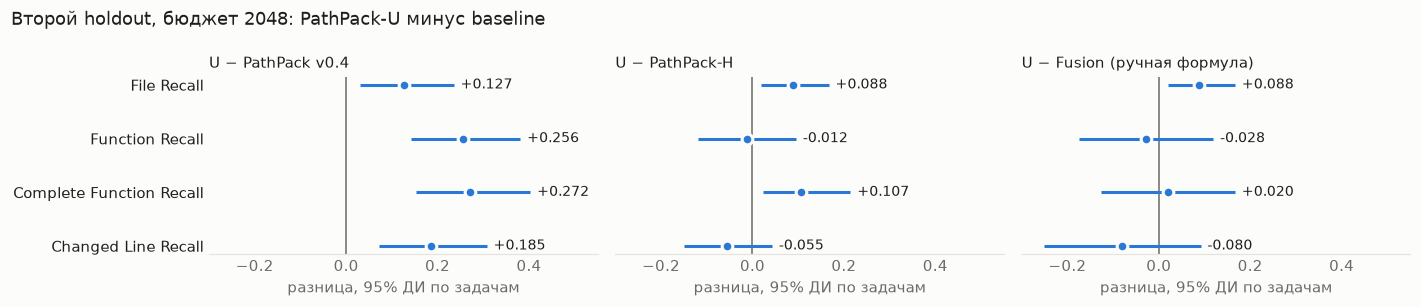

,сравнение,метрика,diff,lo,hi,ДИ по репозиториям,n,победы/ничьи/поражения
0,U − PathPack v0.4,File Recall,0.127,0.029,0.235,"[-0.045, 0.274]",51,8/42/1
1,U − PathPack v0.4,Function Recall,0.256,0.141,0.381,"[0.06, 0.36]",42,14/28/0
2,U − PathPack v0.4,Complete Function Recall,0.272,0.153,0.403,"[0.036, 0.388]",42,14/28/0
3,U − PathPack v0.4,Changed Line Recall,0.185,0.071,0.308,"[-0.015, 0.303]",38,11/25/2
4,U − PathPack-H,File Recall,0.088,0.020,0.167,"[0.0, 0.241]",51,5/46/0
5,U − PathPack-H,Function Recall,-0.012,-0.119,0.095,"[-0.158, 0.033]",42,3/36/3
6,U − PathPack-H,Complete Function Recall,0.107,0.024,0.214,"[0.0, 0.159]",42,5/37/0
7,U − PathPack-H,Changed Line Recall,-0.055,-0.150,0.043,"[-0.16, -0.017]",38,3/30/5
8,U − Fusion (ручная формула),File Recall,0.088,0.020,0.167,"[0.0, 0.119]",51,5/46/0
9,U − Fusion (ручная формула),Function Recall,-0.028,-0.175,0.119,"[-0.261, 0.054]",42,5/30/7


In [12]:
pj = json.load(open(H2 / 'paired.json'))
rows = []
for base in ('pathpack-v4', 'pathpack-h/nomemory', 'pathpack-r/fusion'):
    for key, title in METRICS:
        v = pj[f'pathpack-u vs {base} {key}']
        rows.append({'сравнение': 'U − ' + NAMES[base].replace(' (основной)', ''), 'метрика': title, 'diff': v['difference'], 'lo': v['ci95'][0], 'hi': v['ci95'][1],
                     'ДИ по репозиториям': [round(x, 3) for x in v['ci95_repo_cluster']], 'n': v['n'],
                     'победы/ничьи/поражения': f"{v['wins']}/{v['ties']}/{v['losses']}"})
cmp2 = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8), sharex=True, sharey=True)
for ax, (name, part) in zip(axes, cmp2.groupby('сравнение', sort=False)):
    y = range(len(part))
    ax.axvline(0, color=MUTED, lw=1)
    ax.hlines(y, part.lo, part.hi, color=BLUE, lw=2)
    ax.plot(part['diff'], y, 'o', color=BLUE, ms=7, mec=SURFACE, mew=2)
    for i, r in enumerate(part.itertuples()):
        ax.text(r.hi + 0.015, i, f'{r.diff:+.3f}', va='center', fontsize=9)
    ax.set_yticks(list(y)); ax.set_yticklabels(part['метрика'])
    ax.set_title(name, fontsize=10, loc='left'); ax.tick_params(length=0); ax.set_xlim(-0.3, 0.55)
    ax.set_xlabel('разница, 95% ДИ по задачам')
axes[0].invert_yaxis()
fig.suptitle('Второй holdout, бюджет 2048: PathPack-U минус baseline', x=0.01, ha='left', fontsize=12)
fig.tight_layout(); plt.show()
cmp2.round(3)

## 10. Третий отложенный набор: 125 задач, незнакомые репозитории, проба с Gemma 4

125 задач train-pool, не использовавшихся ни в обучении, ни в оценке (`output/pathpack_holdout3`, заморозка `FREEZE_before_holdout3.json`). «Без своей истории» означает модель, обученную на псевдо-задачах остальных одиннадцати репозиториев (`output/pathpack_holdout3_loro`).

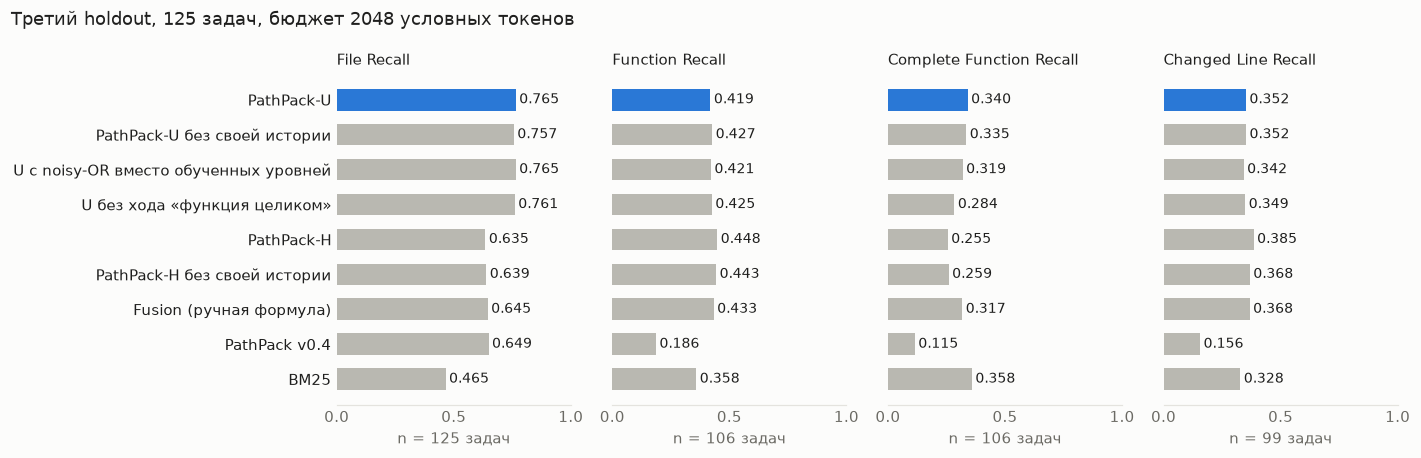

,file_recall,function_recall,complete_function_recall,changed_line_recall
method,,,,
PathPack-U,0.765,0.419,0.340,0.352
PathPack-U без своей истории,0.757,0.427,0.335,0.352
U с noisy-OR вместо обученных уровней,0.765,0.421,0.319,0.342
U без хода «функция целиком»,0.761,0.425,0.284,0.349
PathPack-H (основной),0.635,0.448,0.255,0.385
PathPack-H без своей истории,0.639,0.443,0.259,0.368
Fusion (ручная формула),0.645,0.433,0.317,0.368
PathPack v0.4,0.649,0.186,0.115,0.156
BM25,0.465,0.358,0.358,0.328


In [13]:
H3, H3L = ROOT / 'output/pathpack_holdout3', ROOT / 'output/pathpack_holdout3_loro'
NAMES['pathpack-u/noisyor'] = 'U с noisy-OR вместо обученных уровней'
h3 = summary(H3); h3l = summary(H3L); h3l['method'] = 'loro:' + h3l['method']
NAMES['loro:pathpack-u'] = 'PathPack-U без своей истории'; NAMES['loro:pathpack-h/nomemory'] = 'PathPack-H без своей истории'
both = pd.concat([h3, h3l])
order3 = ['pathpack-u', 'loro:pathpack-u', 'pathpack-u/noisyor', 'pathpack-u/nobundle', 'pathpack-h/nomemory', 'loro:pathpack-h/nomemory', 'pathpack-r/fusion', 'pathpack-v4', 'bm25']
at3 = both[both.budget == 2048].set_index('method').loc[order3]
fig, axes = plt.subplots(1, 4, figsize=(13, 4.2), sharey=True)
for ax, (key, title) in zip(axes, METRICS):
    vals = at3[key].values
    ax.barh(range(len(order3)), vals, height=0.62, color=[BLUE if m == 'pathpack-u' else NEUTRAL for m in order3])
    for i, v in enumerate(vals):
        ax.text(v + 0.015, i, f'{v:.3f}', va='center', fontsize=9, color=INK)
    ax.set_xlim(0, 1); ax.set_title(title, fontsize=10, loc='left', color=INK)
    ax.set_yticks(range(len(order3))); ax.set_yticklabels([NAMES[m].replace(' (основной)', '') for m in order3])
    ax.set_xticks([0, 0.5, 1]); ax.tick_params(length=0)
    ax.set_xlabel(f"n = {int(at3[key + '_evaluable'].iloc[0])} задач")
axes[0].invert_yaxis()
fig.suptitle('Третий holdout, 125 задач, бюджет 2048 условных токенов', x=0.01, ha='left', fontsize=12)
fig.tight_layout(); plt.show()
at3[[k for k, _ in METRICS]].rename(index=NAMES).round(3)

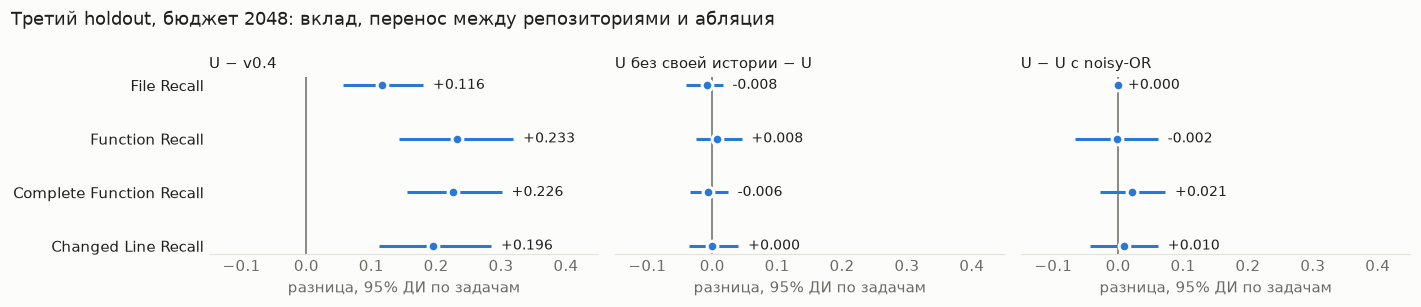

,сравнение,метрика,diff,lo,hi,ДИ по репозиториям,n,победы/ничьи/поражения
0,U − v0.4,File Recall,0.116,0.056,0.180,"[0.1, 0.222]",125,18/105/2
1,U − v0.4,Function Recall,0.233,0.143,0.319,"[0.167, 0.306]",106,35/67/4
2,U − v0.4,Complete Function Recall,0.226,0.156,0.301,"[0.135, 0.251]",106,29/77/0
3,U − v0.4,Changed Line Recall,0.196,0.112,0.285,"[0.087, 0.231]",99,31/61/7
4,U без своей истории − U,File Recall,-0.008,-0.040,0.016,"[-0.036, 0.0]",125,1/122/2
5,U без своей истории − U,Function Recall,0.008,-0.025,0.045,"[-0.039, 0.022]",106,4/99/3
6,U без своей истории − U,Complete Function Recall,-0.006,-0.035,0.024,"[-0.039, 0.003]",106,2/101/3
7,U без своей истории − U,Changed Line Recall,0.000,-0.036,0.040,"[-0.054, 0.017]",99,3/92/4
8,U − U с noisy-OR,File Recall,0.000,0.000,0.000,"[0.0, 0.0]",125,0/125/0
9,U − U с noisy-OR,Function Recall,-0.002,-0.067,0.061,"[-0.033, 0.117]",106,10/88/8


In [14]:
pj3 = json.load(open(H3 / 'paired.json'))
groups = [('U − v0.4', 'pathpack-u vs pathpack-v4'), ('U без своей истории − U', 'loro:pathpack-u vs pathpack-u'),
          ('U − U с noisy-OR', 'pathpack-u vs pathpack-u/noisyor')]
rows = []
for label, key0 in groups:
    for key, title in METRICS:
        v = pj3[f'{key0} {key}']
        rows.append({'сравнение': label, 'метрика': title, 'diff': v['difference'], 'lo': v['ci95'][0], 'hi': v['ci95'][1],
                     'ДИ по репозиториям': [round(x, 3) for x in v['ci95_repo_cluster']], 'n': v['n'],
                     'победы/ничьи/поражения': f"{v['wins']}/{v['ties']}/{v['losses']}"})
cmp3 = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8), sharex=True, sharey=True)
for ax, (name, part) in zip(axes, cmp3.groupby('сравнение', sort=False)):
    y = range(len(part))
    ax.axvline(0, color=MUTED, lw=1)
    ax.hlines(y, part.lo, part.hi, color=BLUE, lw=2)
    ax.plot(part['diff'], y, 'o', color=BLUE, ms=7, mec=SURFACE, mew=2)
    for i, r in enumerate(part.itertuples()):
        ax.text(r.hi + 0.015, i, f'{r.diff:+.3f}', va='center', fontsize=9)
    ax.set_yticks(list(y)); ax.set_yticklabels(part['метрика'])
    ax.set_title(name, fontsize=10, loc='left'); ax.tick_params(length=0); ax.set_xlim(-0.15, 0.45)
    ax.set_xlabel('разница, 95% ДИ по задачам')
axes[0].invert_yaxis()
fig.suptitle('Третий holdout, бюджет 2048: вклад, перенос между репозиториями и абляция', x=0.01, ha='left', fontsize=12)
fig.tight_layout(); plt.show()
cmp3.round(3)

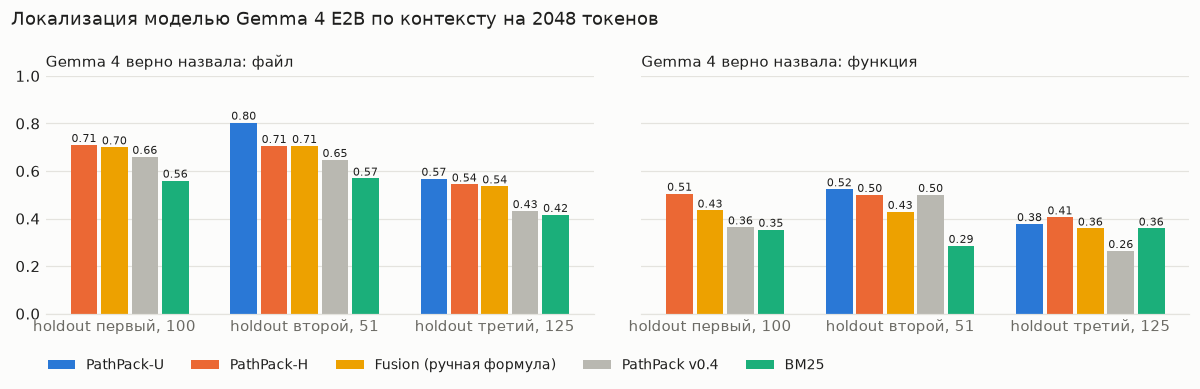

файл                            функция  \
набор                   второй, 51 первый, 100 третий, 125 второй, 51   
method                                                                  
BM25                         0.569        0.56       0.416      0.286   
PathPack-H (основной)        0.706        0.71       0.544      0.500   
Fusion (ручная формула)      0.706        0.70       0.536      0.429   
PathPack-U                   0.804         NaN       0.568      0.524   
PathPack v0.4                0.647        0.66       0.432      0.500   

                                                 
набор                   первый, 100 третий, 125  
method                                           
BM25                          0.354       0.358  
PathPack-H (основной)         0.505       0.406  
Fusion (ручная формула)       0.434       0.358  
PathPack-U                      NaN       0.377  
PathPack v0.4                 0.364       0.264

In [15]:
llm = []
for name, label in [('holdout1', 'первый, 100'), ('holdout2', 'второй, 51'), ('holdout3', 'третий, 125')]:
    d = json.load(open(ROOT / f'output/llm_probe/{name}_summary.json'))
    for m, v in d['summary'].items():
        llm.append({'набор': label, 'method': m, 'файл': v['llm_file_acc'], 'функция': v['llm_function_acc']})
llm = pd.DataFrame(llm)
order_l = ['pathpack-u', 'pathpack-h/nomemory', 'pathpack-r/fusion', 'pathpack-v4', 'bm25']
colors = {'pathpack-u': BLUE, 'pathpack-h/nomemory': ORANGE, 'pathpack-r/fusion': YELLOW, 'pathpack-v4': NEUTRAL, 'bm25': AQUA}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
sets = list(dict.fromkeys(llm['набор']))
for ax, col in zip(axes, ['файл', 'функция']):
    for j, m in enumerate(order_l):
        part = llm[llm.method == m].set_index('набор').reindex(sets)
        xs = [i + (j - 2) * 0.16 for i in range(len(sets))]
        ax.bar(xs, part[col].values, width=0.14, color=colors[m], label=NAMES[m].replace(' (основной)', ''))
        for x, v in zip(xs, part[col].values):
            if pd.notna(v):
                ax.text(x, v + 0.012, f'{v:.2f}', ha='center', fontsize=7, color=INK)
    ax.set_xticks(range(len(sets))); ax.set_xticklabels([f'holdout {s}' for s in sets]); ax.set_ylim(0, 1)
    ax.set_title(f'Gemma 4 верно назвала: {col}', fontsize=10, loc='left'); ax.tick_params(length=0)
    ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=9, ncol=5, loc='lower left', bbox_to_anchor=(0.03, -0.02))
fig.suptitle('Локализация моделью Gemma 4 E2B по контексту на 2048 токенов', x=0.01, ha='left', fontsize=12)
fig.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()
llm.pivot(index='method', columns='набор', values=['файл', 'функция']).rename(index=NAMES).round(3)

## Что из этого следует и чего не следует

- Основной вариант против v0.4 на holdout выше по Function, Complete и Changed Line; интервалы не включают ноль и при bootstrap по репозиториям. По File разница в пределах интервала.
- Против ручного fusion значим только Function Recall. Против PathPack-E различий нет; E обучалась на 34 задачах, сравнение неравное.
- Память коммитов, признаки истории, графовый раунд и скелеты вклада не показали.
- BM25 остаётся выше по Complete Function Recall.
- PathPack-U на втором holdout выше v0.4 по всем четырём метрикам и выше PathPack-H по File; по Function и Changed Line он не лучше PathPack-H и fusion.
- На третьем наборе (125 задач) PathPack-U выше v0.4 по всем четырём метрикам; модели без истории своего репозитория дают те же числа; обученные уровни функции и файла не лучше noisy-OR.
- Gemma 4 с контекстом PathPack-H и PathPack-U чаще верно называет файл и функцию, чем с контекстом v0.4, на третьем наборе.
- Доля исправленных ошибок не измерялась; токены условные; обучение на истории шло по тем же 12 репозиториям, что и оценка.